# 04 · Final model: Bare class, non-European regions and calibrated confidence (dataset v4)

Notebooks 02 and 03 selected `Unet_ctx2` (U-Net, ResNet-34, ±2 months of Sentinel-1) on dataset v3, which only
covers Europe and ignores WorldCover's *bare / sparse vegetation*. Applied to a desert (Cholistan, Pakistan), the
v3 model therefore labelled sand as Grassland with >90 % confidence. This notebook fixes both problems:

1. **Dataset v4** (notebook 01): v3 plus a sixth class **Bare** and 12 non-European regions (deserts, steppe,
   Sahel, cerrado, monsoon farmland). Cholistan is held out completely as an unseen arid test region.
2. **Same architecture and recipe** as the selected v3 model, so the difference comes from the data.
3. **Temperature scaling** on the validation set, so that the confidence shown in the prototype matches the
   observed accuracy (expected calibration error, ECE, before and after).

The v3 model is evaluated on the same v4 test sets as the baseline. It cannot predict Bare, so besides the
6-class mIoU the table reports the mIoU over the five v3 classes. `models/best_model.pth` is replaced only if the
v4 model does not lose more than `MAX_EUROPE_LOSS` mIoU on the European validation blocks.

In [1]:
import random, sys, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

sys.path.insert(0, str(Path.cwd()))
import lulc_common as lc

SEED = 42
EPOCHS = 40
BATCH_SIZE = 16
MAX_LR = 1e-3
GRAD_CLIP = 1.0
N_BOOTSTRAP = 1000
LOADER_THREADS = 12
MAX_EUROPE_LOSS = 1.0           # val mIoU points (5 classes, Europe) the v4 model may lose against v3
LOAD_ALL_YEARS = True           # False: skip holdout/ood years that no evaluation set uses (saves ~4 GB RAM)

NAME = "Unet_ctx2"
VARIANT = dict(arch="Unet", encoder="resnet34", channels=list(lc.CHANNELS), context=2, smooth_labels=False)
BASELINE_PATH = lc.PROJECT_ROOT / "models" / "v3" / "Unet_ctx2.pth"
BASELINE = "v3 Unet_ctx2 + TTA"
GLOBAL_REGIONS = ["jodhpur_india", "nile_benisuef_egypt", "marrakech_morocco", "monegros_spain", "phoenix_usa",
                  "isfahan_iran", "riyadh_saudi", "mendoza_argentina", "niamey_niger", "kashgar_china",
                  "ludhiana_india", "brasilia_brazil"]
EVAL_SPLITS = ["test", "holdout_de", "ood", "holdout_arid"]
EVAL_YEARS = [2021, 2024, 2025]
EVAL_SETS = {                   # label: (split, years, regions: None = all, "europe", "global")
    "test 2021":            ("test", [2021], None),
    "test 2021 Europe":     ("test", [2021], "europe"),
    "test 2021 global":     ("test", [2021], "global"),
    "test 2020–23":         ("test", [2020, 2021, 2022, 2023], None),
    "holdout_de 2021":      ("holdout_de", [2021], None),
    "holdout_de 2024–25":   ("holdout_de", [2024, 2025], None),
    "ood 2021":             ("ood", [2021], None),
    "ood 2024–25":          ("ood", [2024, 2025], None),
    "holdout_arid 2021":    ("holdout_arid", [2021], None),
    "holdout_arid 2024–25": ("holdout_arid", [2024, 2025], None),
}
lc.MODEL_DIR.mkdir(parents=True, exist_ok=True)
lc.FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
amp_dtype = torch.bfloat16 if use_amp and torch.cuda.is_bf16_supported() else torch.float16
print("Device:", device, torch.cuda.get_device_name(0) if use_amp else "", "| AMP dtype:", amp_dtype)
print("Dataset:", lc.DATA_DIR, "| classes:", lc.CLASS_NAMES)

meta = pd.read_csv(lc.DATA_DIR / "patches_meta.csv")
if not LOAD_ALL_YEARS:
    meta = meta[(meta.split.isin(["train", "val", "test"])) | meta.year.isin(EVAL_YEARS)].reset_index(drop=True)
meta["group"] = meta.region + "/" + meta.block
meta["loc"] = meta.region + "/" + meta.y.astype(str) + "/" + meta.x.astype(str)
meta["t"] = meta.year * 12 + meta.month - 1
meta["area"] = np.where(meta.region.isin(GLOBAL_REGIONS + ["cholistan_pakistan"]), "outside Europe", "Europe")
assert meta.region.isin(GLOBAL_REGIONS).any(), "Run 01_build_dataset.ipynb first: no non-European regions found"
assert BASELINE_PATH.exists(), f"{BASELINE_PATH} not found (the v3 model of notebook 03)"

gb = (len(lc.CHANNELS) * 2 + 2) * 256 * 256 / 1e9
overview = meta.pivot_table(index="split", columns="area", values="image", aggfunc="count", fill_value=0)
overview["total"] = overview.sum(axis=1)
overview["share (%)"] = (overview.total / len(meta) * 100).round(1)
overview = overview.reindex(["train", "val", "test"] + EVAL_SPLITS[1:])
print(f"{len(meta)} patches, {meta.region.nunique()} regions, RAM needed ≈ {len(meta) * gb:.0f} GB")
display(overview)
meta.pivot_table(index="split", columns="year", values="image", aggfunc="count", fill_value=0).reindex(overview.index)

Device: cuda NVIDIA RTX A6000 | AMP dtype: torch.bfloat16
Dataset: /home/jovyan/vault/deep_learning/data/v4 | classes: ['Forest', 'Grassland', 'Cropland', 'Urban', 'Water', 'Bare']
114676 patches, 64 regions, RAM needed ≈ 90 GB


area,Europe,outside Europe,total,share (%)
split,,,,
train,58956,9436,68392,59.6
val,11670,2264,13934,12.2
test,17799,2455,20254,17.7
holdout_de,4608,0,4608,4.0
ood,4608,0,4608,4.0
holdout_arid,0,2880,2880,2.5


year,2020,2021,2022,2023,2024,2025
split,,,,,,
train,19378,19446,14784,14784,0,0
val,4034,4044,2928,2928,0,0
test,5656,5670,4464,4464,0,0
holdout_de,768,768,768,768,768,768
ood,768,768,768,768,768,768
holdout_arid,720,720,0,0,720,720


## Load all patches into RAM
As in notebooks 02/03. `NB[d]` points to the same location `d` months away (-2 … +2), or -1.

In [2]:
N = len(meta)
IMAGES = np.empty((N, len(lc.CHANNELS), 256, 256), dtype=np.float16)
MASKS = np.empty((N, 2, 256, 256), dtype=np.uint8)
YEAR = meta.year.to_numpy()
image_paths, mask_paths = meta["image"].tolist(), meta["mask"].tolist()


def _load(i):
    IMAGES[i] = np.load(lc.DATA_DIR / image_paths[i])
    MASKS[i] = np.load(lc.DATA_DIR / mask_paths[i])


t0 = time.time()
with ThreadPoolExecutor(32) as pool:
    for k, _ in enumerate(pool.map(_load, range(N)), 1):
        if k % 20000 == 0 or k == N:
            print(f"loaded {k}/{N} patches ({time.time() - t0:.0f}s)", flush=True)

index_of = {(l, t): i for i, (l, t) in enumerate(zip(meta["loc"], meta["t"]))}
NB = {d: np.array([index_of.get((l, t + d), -1) for l, t in zip(meta["loc"], meta["t"])]) for d in (-2, -1, 1, 2)}
print(f"RAM: {(IMAGES.nbytes + MASKS.nbytes) / 1e9:.1f} GB | neighbour available: "
      + ", ".join(f"{d:+d}: {(NB[d] >= 0).mean():.1%}" for d in NB))

loaded 20000/114676 patches (90s)
loaded 40000/114676 patches (259s)
loaded 60000/114676 patches (514s)
loaded 80000/114676 patches (687s)
loaded 100000/114676 patches (846s)
loaded 114676/114676 patches (961s)
RAM: 90.2 GB | neighbour available: -2: 95.0%, -1: 97.4%, +1: 97.4%, +2: 95.0%


## Class distribution (labelled pixels, WorldCover 2021, one mask per location)

In [3]:
locs = meta[meta.year == 2021].drop_duplicates("loc")
dist = {}
for (split, area), df in locs.groupby(["split", "area"]):
    c = np.zeros(lc.NUM_CLASSES)
    for i in df.index:
        lab = lc.labels_from_raw(MASKS[i])
        c += np.bincount(lab[lab != lc.IGNORE_INDEX], minlength=lc.NUM_CLASSES)
    dist[(split, area)] = c / max(c.sum(), 1) * 100
dist = pd.DataFrame(dist, index=lc.CLASS_NAMES).T.round(1)
dist.to_csv(lc.FIGURE_DIR / "class_distribution.csv")
dist

Forest  Grassland  Cropland  Urban  Water  Bare
holdout_arid outside Europe     1.6        3.9      40.2    0.9    0.2  53.1
holdout_de   Europe            37.3       12.0      22.6   23.3    4.6   0.1
ood          Europe            12.3       19.7      14.7   28.1   23.2   1.9
test         Europe            33.8       17.5      18.2   23.9    6.4   0.2
             outside Europe     8.7       25.8      18.9   25.4    2.2  19.1
train        Europe            37.0       17.3      17.4   23.8    4.5   0.1
             outside Europe     7.8       23.0      17.2   32.1    1.9  18.0
val          Europe            37.0       18.0      16.6   25.3    2.9   0.2
             outside Europe     7.3       20.3      22.1   30.8    0.6  18.8

In [4]:
def get_sample(i, cfg):
    """Network input (C, H, W) float32 and target (H, W) int64 for patch i (any context window)."""
    k = lc.context_months(cfg)
    nb = {}
    for d in [d for d in NB if abs(d) <= k]:
        j = NB[d][i]
        if j >= 0:
            nb[d] = (IMAGES[j].astype(np.float32), MASKS[j, 0] != 0)     # SAR-invalid pixels are code 0
    x = lc.model_input_window(cfg, IMAGES[i].astype(np.float32), nb)
    return x, lc.labels_from_raw(MASKS[i], year=YEAR[i])


def _flip_rot(x, y, rng):
    if rng.random() < 0.5:
        x, y = x[:, :, ::-1], y[:, ::-1]
    if rng.random() < 0.5:
        x, y = x[:, ::-1, :], y[::-1, :]
    k = rng.integers(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k)


class Batches:
    """Threaded batch iterator (identical to notebooks 02/03)."""

    def __init__(self, items, cfg, train=False):
        self.items, self.cfg, self.train = items, cfg, train
        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        n = len(self.items)
        return n // BATCH_SIZE if self.train else -(-n // BATCH_SIZE)

    def _batch(self, chunk, seed):
        rng = np.random.default_rng(seed)
        xs, ys = [], []
        for item in chunk:
            i = rng.choice(item) if self.train else item
            x, y = get_sample(i, self.cfg)
            if self.train:
                x, y = _flip_rot(x, y, rng)
            xs.append(np.ascontiguousarray(x))
            ys.append(np.ascontiguousarray(y))
        return torch.from_numpy(np.stack(xs)), torch.from_numpy(np.stack(ys).astype(np.int64))

    def __iter__(self):
        order = self.rng.permutation(len(self.items)) if self.train else np.arange(len(self.items))
        chunks = [[self.items[j] for j in order[k:k + BATCH_SIZE]] for k in range(0, len(order), BATCH_SIZE)]
        if self.train and len(chunks[-1]) < BATCH_SIZE:
            chunks = chunks[:-1]
        seeds = self.rng.integers(0, 2**31, size=len(chunks))
        with ThreadPoolExecutor(LOADER_THREADS) as pool:
            queue = deque()
            for c, s in zip(chunks, seeds):
                queue.append(pool.submit(self._batch, c, s))
                if len(queue) > 2 * LOADER_THREADS:
                    yield queue.popleft().result()
            while queue:
                yield queue.popleft().result()


def gpu_augment(x):
    x = x + torch.empty(x.shape[0], x.shape[1], 1, 1, device=x.device).uniform_(-0.03, 0.03)
    return (x + 0.01 * torch.randn_like(x)).clamp_(0.0, 1.0)


train_idx = meta.index[meta.split == "train"].to_numpy()
train_groups = [train_idx[g] for g in meta.loc[train_idx].groupby(["loc", "month"]).indices.values()]
val_idx = meta.index[meta.split == "val"].to_numpy()
val_europe = meta.index[(meta.split == "val") & (meta.area == "Europe")].to_numpy()
val_global = meta.index[(meta.split == "val") & (meta.area != "Europe")].to_numpy()

px = np.zeros(lc.NUM_CLASSES)
for i in np.random.default_rng(SEED).choice(train_idx, min(len(train_idx), 10000), replace=False):
    lab = lc.labels_from_raw(MASKS[i], year=YEAR[i])
    px += np.bincount(lab[lab != lc.IGNORE_INDEX], minlength=lc.NUM_CLASSES)
class_weights = 1.0 / np.sqrt(px / px.sum())
class_weights = class_weights / class_weights.mean()
print(f"training: {len(train_groups)} location-months | validation: {len(val_idx)} patches "
      f"({len(val_global)} outside Europe) | class weights {dict(zip(lc.CLASS_NAMES, np.round(class_weights, 2)))}")

training: 19584 location-months | validation: 13934 patches (2264 outside Europe) | class weights {'Forest': np.float64(0.53), 'Grassland': np.float64(0.74), 'Cropland': np.float64(0.73), 'Urban': np.float64(0.62), 'Water': np.float64(1.48), 'Bare': np.float64(1.91)}


In [5]:
ce_loss = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device),
                              ignore_index=lc.IGNORE_INDEX)
dice_loss = smp.losses.DiceLoss(mode="multiclass", ignore_index=lc.IGNORE_INDEX)


def criterion(logits, target):
    return 0.5 * ce_loss(logits, target) + 0.5 * dice_loss(logits, target)


@torch.no_grad()
def evaluate(model, batches, with_loss=True):
    model.eval()
    n = lc.NUM_CLASSES
    cm = torch.zeros(n * n, dtype=torch.long, device=device)
    total_loss, count = 0.0, 0
    for x, y in batches:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            logits = model(x)
        if with_loss:
            total_loss += criterion(logits.float(), y).item()
        count += 1
        keep = y != lc.IGNORE_INDEX
        cm += torch.bincount(y[keep] * n + logits.argmax(1)[keep], minlength=n * n)
    return total_loss / max(count, 1), cm.view(n, n).cpu().numpy()


def train_variant(name, cfg):
    seed_everything(SEED)
    train_batches = Batches(train_groups, cfg, train=True)
    val_batches = Batches(val_idx, cfg)
    model = lc.build_model(cfg["arch"], cfg["encoder"], lc.n_input_channels(cfg), encoder_weights="imagenet").to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=MAX_LR, pct_start=0.1,
                                                    total_steps=EPOCHS * len(train_batches))
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp and amp_dtype == torch.float16)
    ckpt_cfg = {"name": name, **cfg, "class_names": lc.CLASS_NAMES, "db_ranges": lc.DB_RANGES,
                "max_scenes_per_month": lc.MAX_SCENES_PER_MONTH, "dataset": lc.DATASET_VERSION,
                "label_rule": f"{lc.LABEL_YEAR}: full WorldCover {lc.LABEL_YEAR}; other years: 2020/2021-stable pixels",
                "train": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "max_lr": MAX_LR, "seed": SEED,
                          "years": sorted(meta.loc[train_idx, "year"].unique().tolist()),
                          "regions": int(meta.loc[train_idx, "region"].nunique())}}
    history, best_miou = [], -1.0
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        model.train()
        running = 0.0
        for x, y in train_batches:
            x, y = gpu_augment(x.to(device, non_blocking=True)), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
                logits = model(x)
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()
        val_loss, cm = evaluate(model, val_batches)
        m = lc.metrics_from_confusion(cm)
        history.append({"epoch": epoch, "lr": scheduler.get_last_lr()[0], "train_loss": running / len(train_batches),
                        "val_loss": val_loss, "val_OA": m["OA"], "val_mIoU": m["mIoU"], "val_Bare_IoU": m["IoU"][5]})
        improved = m["mIoU"] > best_miou
        if improved:
            best_miou = m["mIoU"]
            torch.save({"config": ckpt_cfg, "state_dict": model.state_dict(), "epoch": epoch,
                        "val_mIoU": best_miou}, lc.MODEL_DIR / f"{name}.pth")
        print(f"[{name}] epoch {epoch:02d} | lr {history[-1]['lr']:.1e} | train {history[-1]['train_loss']:.4f} | "
              f"val {val_loss:.4f} | OA {m['OA']:.4f} | mIoU {m['mIoU']:.4f} | Bare IoU {m['IoU'][5]:.4f}"
              f"{' *' if improved else ''} | {time.time() - t0:.0f}s", flush=True)
    history = pd.DataFrame(history)
    history.to_csv(lc.FIGURE_DIR / f"history_{name}.csv", index=False)
    return history, best_miou

## Train `Unet_ctx2` on dataset v4
Resumable: a finished run is loaded instead of retrained (≈ 80 min on the A6000).

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

[Unet_ctx2] epoch 01 | lr 1.8e-04 | train 0.7187 | val 0.6409 | OA 0.7366 | mIoU 0.5574 | Bare IoU 0.2538 * | 215s
[Unet_ctx2] epoch 02 | lr 5.2e-04 | train 0.5489 | val 0.5958 | OA 0.7433 | mIoU 0.5758 | Bare IoU 0.3213 * | 186s
[Unet_ctx2] epoch 03 | lr 8.6e-04 | train 0.5165 | val 0.6089 | OA 0.7406 | mIoU 0.5605 | Bare IoU 0.2757 | 151s
[Unet_ctx2] epoch 04 | lr 1.0e-03 | train 0.4943 | val 0.5799 | OA 0.7569 | mIoU 0.6012 | Bare IoU 0.3809 * | 171s
[Unet_ctx2] epoch 05 | lr 1.0e-03 | train 0.4687 | val 0.5447 | OA 0.7741 | mIoU 0.6177 | Bare IoU 0.3629 * | 194s
[Unet_ctx2] epoch 06 | lr 9.9e-04 | train 0.4549 | val 0.5753 | OA 0.7577 | mIoU 0.5998 | Bare IoU 0.3473 | 211s
[Unet_ctx2] epoch 07 | lr 9.8e-04 | train 0.4396 | val 0.5092 | OA 0.7867 | mIoU 0.6430 | Bare IoU 0.4250 * | 213s
[Unet_ctx2] epoch 08 | lr 9.7e-04 | train 0.4306 | val 0.5069 | OA 0.7920 | mIoU 0.6430 | Bare IoU 0.3973 * | 210s
[Unet_ctx2] epoch 09 | lr 9.5e-04 | train 0.4162 | val 0.5118 | OA 0.7912 | mIoU 0.6

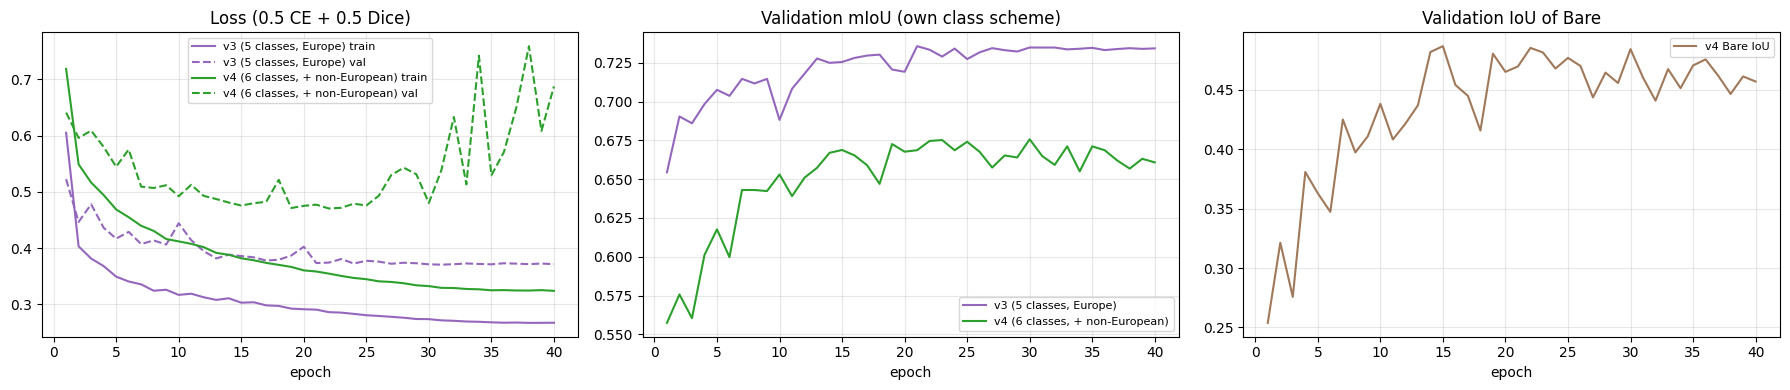

In [6]:
if (lc.FIGURE_DIR / f"history_{NAME}.csv").exists() and (lc.MODEL_DIR / f"{NAME}.pth").exists():
    print(f"==> {NAME}: loaded finished run")
else:
    t0 = time.time()
    _, best = train_variant(NAME, VARIANT)
    print(f"==> {NAME}: best val mIoU {best:.4f} in {(time.time() - t0) / 60:.1f} min\n")

h4 = pd.read_csv(lc.FIGURE_DIR / f"history_{NAME}.csv")
h3_path = lc.PROJECT_ROOT / "figures" / "v3" / f"history_{NAME}.csv"
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for h, label, color in [(pd.read_csv(h3_path) if h3_path.exists() else None, "v3 (5 classes, Europe)", "tab:purple"),
                        (h4, "v4 (6 classes, + non-European)", "tab:green")]:
    if h is None:
        continue
    axes[0].plot(h.epoch, h.train_loss, color=color, label=f"{label} train")
    axes[0].plot(h.epoch, h.val_loss, color=color, linestyle="--", label=f"{label} val")
    axes[1].plot(h.epoch, h.val_mIoU, color=color, label=label)
axes[2].plot(h4.epoch, h4.val_Bare_IoU, color="#a0785a", label="v4 Bare IoU")
for ax, title in zip(axes, ["Loss (0.5 CE + 0.5 Dice)", "Validation mIoU (own class scheme)", "Validation IoU of Bare"]):
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(lc.FIGURE_DIR / "training_curves.png", dpi=150)
plt.show()

## Confidence calibration (temperature scaling)
A segmentation network trained with cross-entropy is usually over-confident. One scalar `T` is fitted on the
validation set (logits / T, minimising the negative log-likelihood); it changes the confidence values, never the
predicted class. The expected calibration error (ECE) is the average gap between confidence and accuracy.

3,567,104 validation pixels | temperature T = 1.277 | ECE 4.97% -> 0.73% | mean confidence 85.4% -> 81.4% | accuracy 80.8%


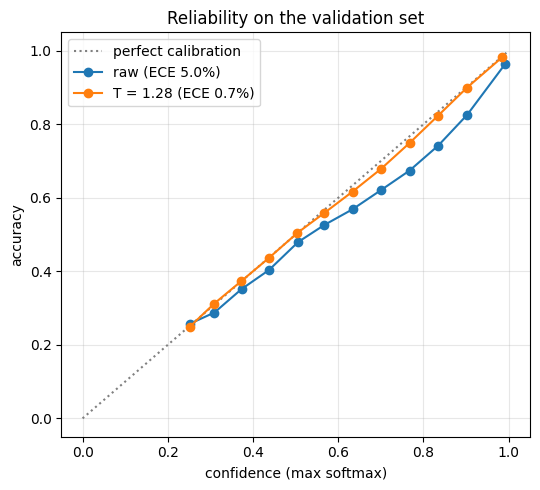

In [7]:
ckpt = torch.load(lc.MODEL_DIR / f"{NAME}.pth", map_location="cpu", weights_only=False)
ckpt["config"].pop("temperature", None)          # re-runs fit T on the raw logits again
model, cfg = lc.load_checkpoint(ckpt, device)


@torch.no_grad()
def collect_logits(model, cfg, idx, px_per_patch=512):
    g = torch.Generator(device=device).manual_seed(SEED)
    L, Y = [], []
    for x, y in Batches(idx, cfg):
        x, y = x.to(device), y.to(device)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            logits = model(x).float()
        logits = logits.permute(0, 2, 3, 1).reshape(-1, logits.shape[1])
        y = y.reshape(-1)
        keep = (y != lc.IGNORE_INDEX).nonzero().squeeze(1)
        keep = keep[torch.randperm(len(keep), generator=g, device=device)[:px_per_patch * x.shape[0]]]
        L.append(logits[keep])
        Y.append(y[keep])
    return torch.cat(L), torch.cat(Y)


def ece(prob, y, n_bins=15):
    conf, pred = prob.max(1)
    correct = (pred == y).float()
    bins = torch.clamp((conf * n_bins).long(), max=n_bins - 1)
    total = torch.zeros(n_bins, device=prob.device).index_add_(0, bins, torch.ones_like(conf))
    acc = torch.zeros(n_bins, device=prob.device).index_add_(0, bins, correct) / total.clamp(min=1)
    mean_conf = torch.zeros(n_bins, device=prob.device).index_add_(0, bins, conf) / total.clamp(min=1)
    return float((total / total.sum() * (acc - mean_conf).abs()).sum()), acc.cpu().numpy(), \
        mean_conf.cpu().numpy(), total.cpu().numpy()


logits, y = collect_logits(model, cfg, val_idx[::2])
log_t = torch.zeros(1, device=device, requires_grad=True)
opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100)


def closure():
    opt.zero_grad()
    loss = nn.functional.cross_entropy(logits / log_t.exp(), y)
    loss.backward()
    return loss


opt.step(closure)
TEMPERATURE = log_t.detach().exp().item()
ece_before, acc_b, conf_b, n_b = ece(torch.softmax(logits, 1), y)
ece_after, acc_a, conf_a, n_a = ece(torch.softmax(logits / TEMPERATURE, 1), y)
print(f"{len(y):,} validation pixels | temperature T = {TEMPERATURE:.3f} | "
      f"ECE {ece_before * 100:.2f}% -> {ece_after * 100:.2f}% | mean confidence "
      f"{torch.softmax(logits, 1).max(1)[0].mean() * 100:.1f}% -> "
      f"{torch.softmax(logits / TEMPERATURE, 1).max(1)[0].mean() * 100:.1f}% | "
      f"accuracy {(logits.argmax(1) == y).float().mean() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="perfect calibration")
ax.plot(conf_b[n_b > 0], acc_b[n_b > 0], "o-", label=f"raw (ECE {ece_before * 100:.1f}%)")
ax.plot(conf_a[n_a > 0], acc_a[n_a > 0], "o-", label=f"T = {TEMPERATURE:.2f} (ECE {ece_after * 100:.1f}%)")
ax.set_xlabel("confidence (max softmax)")
ax.set_ylabel("accuracy")
ax.set_title("Reliability on the validation set")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(lc.FIGURE_DIR / "calibration.png", dpi=150)
plt.show()
del logits, y
ckpt["config"]["temperature"] = TEMPERATURE
ckpt["config"]["ece"] = {"before": ece_before, "after": ece_after}
torch.save(ckpt, lc.MODEL_DIR / f"{NAME}.pth")
model, cfg = lc.load_checkpoint(ckpt, device)

## Validation: v4 against the v3 model
Without TTA, as in model selection. `mIoU 5 classes` averages the IoU of the five v3 classes, so both models are
compared on what v3 can predict; on non-European blocks the v3 model also misses every Bare pixel.

In [8]:
baseline_ckpt = torch.load(BASELINE_PATH, map_location="cpu", weights_only=False)
baseline, baseline_cfg = lc.load_checkpoint(baseline_ckpt, device)


def iou5(m):
    return m["IoU"][:5].mean() * 100


val_rows = {}
for label, mdl, c in [("v3 Unet_ctx2", baseline, baseline_cfg), ("v4 Unet_ctx2", model, cfg)]:
    for part, idx in [("Europe", val_europe), ("outside Europe", val_global)]:
        _, cm = evaluate(mdl, Batches(idx, c), with_loss=False)
        m = lc.metrics_from_confusion(cm)
        val_rows[(label, part)] = {"OA (%)": m["OA"] * 100, "mIoU 6 classes (%)": m["mIoU"] * 100,
                                   "mIoU 5 classes (%)": iou5(m), "Bare IoU (%)": m["IoU"][5] * 100}
val_df = pd.DataFrame(val_rows).T.round(2)
val_df.to_csv(lc.FIGURE_DIR / "validation_v3_v4.csv")
europe_loss = (val_df.loc[("v3 Unet_ctx2", "Europe"), "mIoU 5 classes (%)"]
               - val_df.loc[("v4 Unet_ctx2", "Europe"), "mIoU 5 classes (%)"])
print(f"Europe, 5 classes: v4 is {-europe_loss:+.2f} mIoU points against v3 (allowed: -{MAX_EUROPE_LOSS})")
val_df

Europe, 5 classes: v4 is -1.05 mIoU points against v3 (allowed: -1.0)


OA (%)  mIoU 6 classes (%)  mIoU 5 classes (%)  \
v3 Unet_ctx2 Europe           82.80               61.21               73.45   
             outside Europe   51.00               32.28               38.73   
v4 Unet_ctx2 Europe           82.08               61.41               72.40   
             outside Europe   75.99               56.53               57.56   

                             Bare IoU (%)  
v3 Unet_ctx2 Europe                  0.00  
             outside Europe          0.00  
v4 Unet_ctx2 Europe                  6.43  
             outside Europe         51.39

## Test, held-out and out-of-distribution evaluation (with TTA, as in the app)
Same metrics and block bootstrap as notebooks 02/03, on the v4 sets. `test 2021 global` are the test blocks of
the non-European training regions; `holdout_arid` is Cholistan (Pakistan), never seen in training.

In [9]:
ev = meta[meta.split.isin(EVAL_SPLITS)].copy()
EVAL_IDX = ev.index.to_numpy()
ev["pos"] = np.arange(len(ev))


@torch.no_grad()
def predict(model, cfg, tta=True):
    model.eval()
    n = lc.NUM_CLASSES
    cms, preds = [], []
    for x, y in Batches(EVAL_IDX, cfg):
        x, y = x.to(device), y.to(device)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            p = (lc.predict_tta(model, x) if tta else model(x)).argmax(1)
        b = y.shape[0]
        keep = y != lc.IGNORE_INDEX
        patch_idx = torch.arange(b, device=device).view(b, 1, 1).expand_as(y)
        idx = patch_idx[keep] * n * n + y[keep] * n + p[keep]
        cms.append(torch.bincount(idx, minlength=b * n * n).view(b, n, n).cpu().numpy())
        preds.append(p.cpu().numpy().astype(np.uint8))
    return np.concatenate(cms), np.concatenate(preds)


def metrics_vec(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1).astype(np.float64)
    iou = tp / np.maximum(cm.sum(-1) + cm.sum(-2) - tp, 1)
    return tp.sum(-1) / np.maximum(cm.sum((-1, -2)), 1), iou.mean(-1)


def bootstrap_ci(patch_cms, groups, n_boot=N_BOOTSTRAP):
    keys, inv = np.unique(groups, return_inverse=True)
    block_cms = np.zeros((len(keys),) + patch_cms.shape[1:], dtype=np.int64)
    np.add.at(block_cms, inv, patch_cms)
    rng = np.random.default_rng(SEED)
    samples = block_cms[rng.integers(0, len(keys), size=(n_boot, len(keys)))].sum(1)
    oa, miou = metrics_vec(samples)
    return np.percentile(oa, [2.5, 97.5]) * 100, np.percentile(miou, [2.5, 97.5]) * 100


def set_mask(split, years, regions=None):
    mask = (ev.split == split) & ev.year.isin(years)
    if regions == "europe":
        mask &= ev.area == "Europe"
    elif regions == "global":
        mask &= ev.area != "Europe"
    return mask.to_numpy()


def result_row(name, cms, label, mask):
    cms_m = cms[mask]
    m = lc.metrics_from_confusion(cms_m.sum(0))
    (oa_lo, oa_hi), (mi_lo, mi_hi) = bootstrap_ci(cms_m, ev["group"].to_numpy()[mask])
    row = {"model": name, "set": label, "OA (%)": m["OA"] * 100, "OA 95% CI": f"{oa_lo:.1f}–{oa_hi:.1f}",
           "mIoU (%)": m["mIoU"] * 100, "mIoU 95% CI": f"{mi_lo:.1f}–{mi_hi:.1f}", "mIoU 5 classes (%)": iou5(m)}
    for c, cname in enumerate(lc.CLASS_NAMES):
        row[f"{cname} IoU"] = m["IoU"][c] * 100
        row[f"{cname} F1"] = m["F1"][c] * 100
    return row


patch_cms, preds = {}, {}
for run_name, mdl, c in [(BASELINE, baseline, baseline_cfg), (f"{NAME} + TTA", model, cfg)]:
    t0 = time.time()
    patch_cms[run_name], preds[run_name] = predict(mdl, c)
    print(f"evaluated {run_name} ({time.time() - t0:.0f}s)")
del baseline
torch.cuda.empty_cache()

results_df = pd.DataFrame([result_row(run, cms, label, set_mask(*spec))
                           for run, cms in patch_cms.items() for label, spec in EVAL_SETS.items()]).round(2)
results_df.to_csv(lc.FIGURE_DIR / "results.csv", index=False)
compare = list(patch_cms)
print("=========== TEST SET 2021 (95 % CI: bootstrap over blocks) ===========")
display(results_df[results_df.set == "test 2021"].drop(columns="set").set_index("model"))
print("=========== ALL EVALUATION SETS ===========")
display(results_df.pivot(index="set", columns="model", values=["mIoU (%)", "mIoU 5 classes (%)", "Bare IoU"])
        .reindex(EVAL_SETS).round(1))

evaluated v3 Unet_ctx2 + TTA (259s)
evaluated Unet_ctx2 + TTA (294s)
=========== TEST SET 2021 (95 % CI: bootstrap over blocks) ===========


,OA (%),OA 95% CI,mIoU (%),mIoU 95% CI,mIoU 5 classes (%),Forest IoU,Forest F1,Grassland IoU,Grassland F1,Cropland IoU,Cropland F1,Urban IoU,Urban F1,Water IoU,Water F1,Bare IoU,Bare F1
model,,,,,,,,,,,,,,,,,
v3 Unet_ctx2 + TTA,73.73,70.7–76.5,54.23,51.7–56.5,65.07,59.56,74.66,49.69,66.39,71.01,83.05,59.44,74.56,85.65,92.27,0.00,0.0
Unet_ctx2 + TTA,78.37,77.0–79.7,65.69,63.2–67.8,69.04,62.97,77.28,58.07,73.48,75.46,86.01,62.31,76.78,86.38,92.69,48.92,65.7


=========== ALL EVALUATION SETS ===========


mIoU (%)                    mIoU 5 classes (%)  \
model                Unet_ctx2 + TTA v3 Unet_ctx2 + TTA    Unet_ctx2 + TTA   
set                                                                          
test 2021                       65.7               54.2               69.0   
test 2021 Europe                59.6               60.0               70.8   
test 2021 global                56.4               34.5               57.3   
test 2020–23                    69.2               58.8               72.9   
holdout_de 2021                 58.7               58.4               69.8   
holdout_de 2024–25              61.7               61.8               73.9   
ood 2021                        46.0               48.2               54.1   
ood 2024–25                     49.4               49.4               58.3   
holdout_arid 2021               22.3               17.8               23.1   
holdout_arid 2024–25            25.4               18.5               25.5   

                                               Bare IoU                     
model                v3 Unet_ctx2 + TTA Unet_ctx2 + TTA v3 Unet_ctx2 + TTA  
set                                                                         
test 2021                          65.1            48.9                0.0  
test 2021 Europe                   72.0             3.5                0.0  
test 2021 global                   41.4            51.7                0.0  
test 2020–23                       70.5            50.6                0.0  
holdout_de 2021                    70.1             3.2                0.0  
holdout_de 2024–25                 74.2             0.6                0.0  
ood 2021                           57.8             5.8                0.0  
ood 2024–25                        59.3             4.9                0.0  
holdout_arid 2021                  21.4            18.5                0.0  
holdout_arid 2024–25               22.2            24.9                0.0

## Confusion matrices of the v4 model (2021, % of each true class)

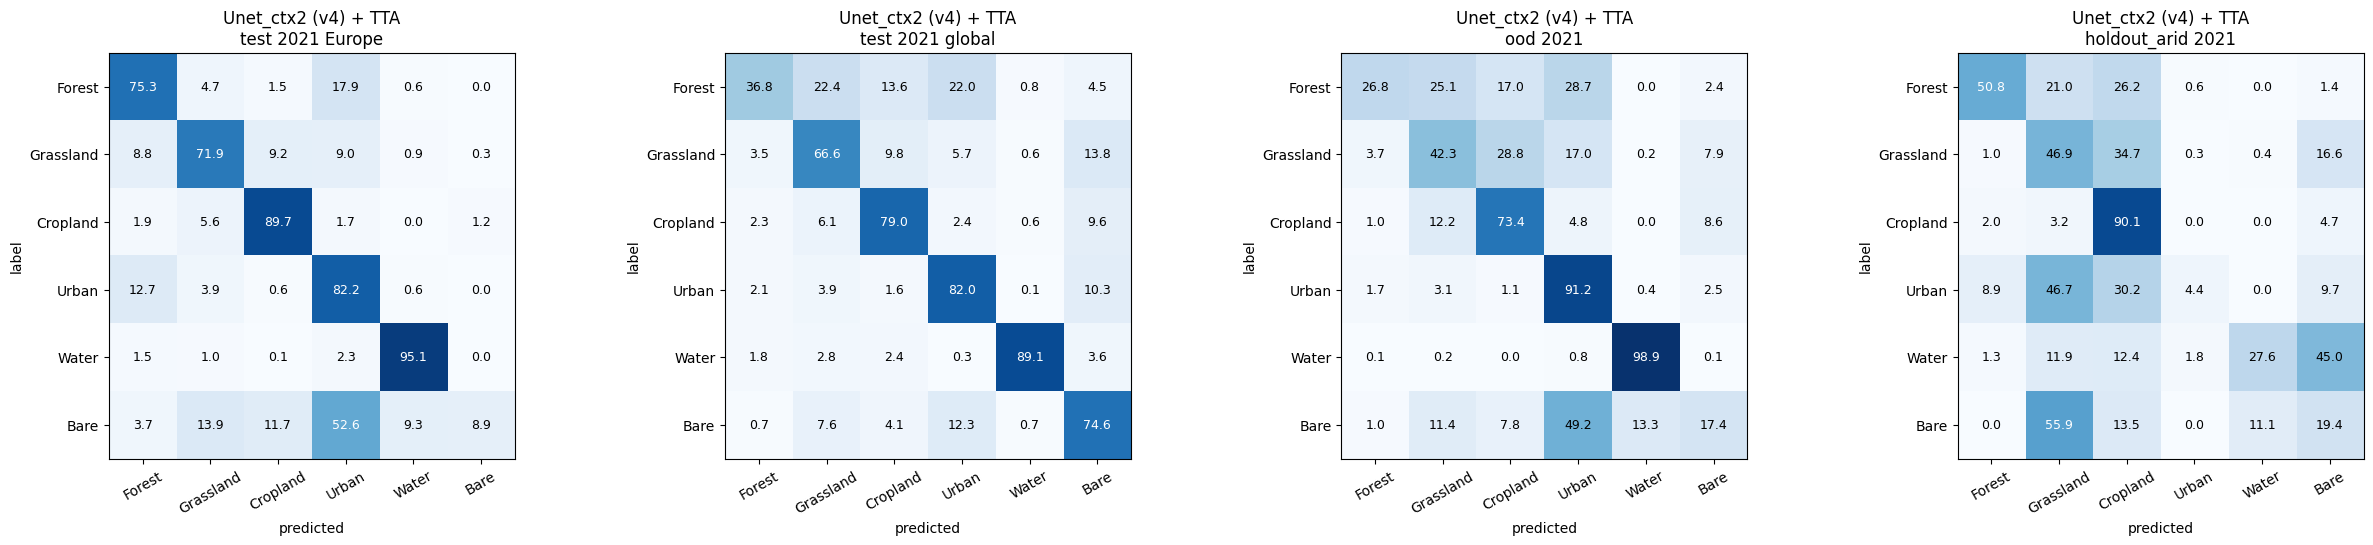

In [10]:
cm_sets = ["test 2021 Europe", "test 2021 global", "ood 2021", "holdout_arid 2021"]
fig, axes = plt.subplots(1, len(cm_sets), figsize=(6.2 * len(cm_sets), 5.5))
for ax, label in zip(axes, cm_sets):
    cm = patch_cms[f"{NAME} + TTA"][set_mask(*EVAL_SETS[label])].sum(0)
    cm_pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(lc.NUM_CLASSES):
        for j in range(lc.NUM_CLASSES):
            ax.text(j, i, f"{cm_pct[i, j]:.1f}", ha="center", va="center", fontsize=9,
                    color="white" if cm_pct[i, j] > 50 else "black")
    ax.set_xticks(range(lc.NUM_CLASSES), lc.CLASS_NAMES, rotation=30)
    ax.set_yticks(range(lc.NUM_CLASSES), lc.CLASS_NAMES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("label")
    ax.set_title(f"{NAME} (v4) + TTA\n{label}")
plt.tight_layout()
plt.savefig(lc.FIGURE_DIR / "confusion_matrices.png", dpi=150)
plt.show()

## False change (true change ≈ 0 on these labels)
Same procedure as notebooks 02/03: the apparent change the prototype would report on unchanged land.

In [11]:
def change_stats(run_name, split, year):
    p_all = preds[run_name]
    rows = []
    df = ev[(ev.split == split) & (ev.year == year)]
    for _, loc in df.groupby("loc"):
        if len(loc) < 12:
            continue
        loc = loc.sort_values("month")
        p = p_all[loc.pos.to_numpy()].copy()
        unlabelled = np.any([lc.labels_from_raw(MASKS[i], year=year) == lc.IGNORE_INDEX for i in loc.index], axis=0)
        p[:, unlabelled] = lc.IGNORE_INDEX
        pct = np.stack([lc.class_percentages(q) for q in p])
        flips = [((a != b) & (a != lc.IGNORE_INDEX)).sum() / max((a != lc.IGNORE_INDEX).sum(), 1) * 100
                 for a, b in zip(p[:-1], p[1:])]
        rows.append({**{f"{n} |m2m| pp": np.abs(np.diff(pct[:, c])).mean() for c, n in enumerate(lc.CLASS_NAMES)},
                     **{f"{n} |first→last| pp": abs(pct[-1, c] - pct[0, c]) for c, n in enumerate(lc.CLASS_NAMES)},
                     **{f"{n} range pp": pct[:, c].max() - pct[:, c].min() for c, n in enumerate(lc.CLASS_NAMES)},
                     "mean class |m2m| pp": np.abs(np.diff(pct, axis=0)).mean(),
                     "pixels changing class per month (%)": np.mean(flips)})
    if not rows:                                   # no location with all 12 months in this set
        return pd.Series({"pixels changing class per month (%)": np.nan})
    return pd.DataFrame(rows).mean()


change_sets = [("test", 2021), ("holdout_de", 2021), ("holdout_de", 2025), ("ood", 2021),
               ("holdout_arid", 2021), ("holdout_arid", 2025)]
change_df = pd.DataFrame({(run, f"{s} {y}"): change_stats(run, s, y) for run in preds for s, y in change_sets}).T
change_df.index.names = ["model", "set"]
change_df = change_df.round(2).reset_index()
change_df.to_csv(lc.FIGURE_DIR / "spurious_change.csv", index=False)
print("Pixels changing class per month (%) — lower is more stable:")
change_df.pivot(index="model", columns="set", values="pixels changing class per month (%)").reindex(compare)

Pixels changing class per month (%) — lower is more stable:


set,holdout_arid 2021,holdout_arid 2025,holdout_de 2021,holdout_de 2025,ood 2021,test 2021
model,,,,,,
v3 Unet_ctx2 + TTA,7.78,5.27,4.46,3.4,5.76,5.46
Unet_ctx2 + TTA,9.90,7.37,4.30,3.4,6.82,5.40


## Final model → prototype
The calibrated v4 model replaces `models/best_model.pth` unless it is clearly worse in Europe (validation).

In [12]:
if europe_loss > MAX_EUROPE_LOSS:
    print(f"v4 loses {europe_loss:.2f} mIoU points in Europe (> {MAX_EUROPE_LOSS}); models/best_model.pth unchanged. "
          f"The v4 model is kept in {lc.MODEL_DIR / (NAME + '.pth')}.")
else:
    torch.save(ckpt, lc.BEST_MODEL_PATH)
    print(f"New best model: {NAME} (dataset v4, 6 classes, T = {TEMPERATURE:.2f}) -> {lc.BEST_MODEL_PATH} "
          f"({lc.BEST_MODEL_PATH.stat().st_size / 1e6:.0f} MB)")
summary = results_df[results_df.set.isin(["test 2021 Europe", "test 2021 global", "holdout_de 2021", "ood 2021",
                                          "holdout_arid 2021", "holdout_arid 2024–25"])]
summary.pivot(index="set", columns="model", values="mIoU (%)").reindex(summary.set.unique()).round(1)

v4 loses 1.05 mIoU points in Europe (> 1.0); models/best_model.pth unchanged. The v4 model is kept in /home/jovyan/vault/deep_learning/models/v4/Unet_ctx2.pth.


model,Unet_ctx2 + TTA,v3 Unet_ctx2 + TTA
set,,
test 2021 Europe,59.6,60.0
test 2021 global,56.4,34.5
holdout_de 2021,58.7,58.4
ood 2021,46.0,48.2
holdout_arid 2021,22.3,17.8
holdout_arid 2024–25,25.4,18.5
